In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    average_precision_score
)

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "dataset" / "vehicle_dataset"
TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"

OUTPUT_DIR = PROJECT_DIR / "outputs"
MODEL_DIR = PROJECT_DIR / "models"

OUTPUT_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

device = torch.device("cpu")

print("Device:", device)
print("Project:", PROJECT_DIR)

Device: cpu
Project: c:\Users\divya\OneDrive\Desktop\CV_task_i2v


In [3]:
# Recreate training dataframe directly from dataset folders

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

train_files = []

for class_dir in sorted(TRAIN_DIR.iterdir()):
    if not class_dir.is_dir():
        continue

    for path in class_dir.iterdir():
        if path.suffix.lower() in IMAGE_EXTENSIONS:
            train_files.append({
                "path": str(path),
                "label": class_dir.name
            })

train_df = pd.DataFrame(train_files)

# Create validation dataframe
val_files = []

for class_dir in sorted(VAL_DIR.iterdir()):
    if not class_dir.is_dir():
        continue

    for path in class_dir.iterdir():
        if path.suffix.lower() in IMAGE_EXTENSIONS:
            val_files.append({
                "path": str(path),
                "label": class_dir.name
            })

val_df = pd.DataFrame(val_files)

# Class mapping
classes = sorted(train_df["label"].unique())

class_to_idx = {
    name: idx for idx, name in enumerate(classes)
}

idx_to_class = {
    idx: name for name, idx in class_to_idx.items()
}

# Save the manifests now
train_df.to_csv(
    OUTPUT_DIR / "cleaned_train_manifest.csv",
    index=False
)

val_df.to_csv(
    OUTPUT_DIR / "validation_manifest.csv",
    index=False
)

print("Train images:", len(train_df))
print("Validation images:", len(val_df))
print("Number of classes:", len(classes))
print("Training manifest saved:", 
      (OUTPUT_DIR / "cleaned_train_manifest.csv").exists())

Train images: 2719
Validation images: 765
Number of classes: 12
Training manifest saved: True


In [4]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


class LetterboxTransform:
    def __init__(self, size=224):
        self.size = size

    def __call__(self, image):
        image = image.convert("RGB")

        scale = min(
            self.size / image.width,
            self.size / image.height
        )

        new_width = max(1, int(image.width * scale))
        new_height = max(1, int(image.height * scale))

        image = image.resize(
            (new_width, new_height),
            Image.Resampling.LANCZOS
        )

        canvas = Image.new(
            "RGB",
            (self.size, self.size),
            (0, 0, 0)
        )

        x = (self.size - new_width) // 2
        y = (self.size - new_height) // 2

        canvas.paste(image, (x, y))

        return canvas


train_transform = transforms.Compose([
    LetterboxTransform(224),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

val_transform = transforms.Compose([
    LetterboxTransform(224),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

In [5]:
class VehicleDataset(Dataset):

    def __init__(self, dataframe, transform, class_to_idx):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform
        self.class_to_idx = class_to_idx

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        with Image.open(row["path"]) as img:
            image = img.convert("RGB")

        image = self.transform(image)

        label = self.class_to_idx[row["label"]]

        return image, label

In [6]:
train_dataset = VehicleDataset(
    train_df,
    train_transform,
    class_to_idx
)

val_dataset = VehicleDataset(
    val_df,
    val_transform,
    class_to_idx
)

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

images, labels = next(iter(train_loader))

print("Batch shape:", images.shape)
print("Labels shape:", labels.shape)
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Batch shape: torch.Size([16, 3, 224, 224])
Labels shape: torch.Size([16])
Train batches: 170
Validation batches: 48


### Load Pretrained model- MobileNetV3-Small

In [7]:
from torchvision.models import (
    mobilenet_v3_small,
    MobileNet_V3_Small_Weights
)

# Load ImageNet-pretrained weights
weights = MobileNet_V3_Small_Weights.DEFAULT

model = mobilenet_v3_small(weights=weights)

# Replace the final classifier for our 12 vehicle classes
in_features = model.classifier[3].in_features

model.classifier[3] = nn.Linear(
    in_features,
    len(classes)
)

model = model.to(device)

print(model.classifier)
print("\nNumber of classes:", len(classes))
print("Device:", device)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to C:\Users\divya/.cache\torch\hub\checkpoints\mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:01<00:00, 5.65MB/s]


Sequential(
  (0): Linear(in_features=576, out_features=1024, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1024, out_features=12, bias=True)
)

Number of classes: 12
Device: cpu


### calculate class weights

In [8]:
# Count training samples for each class
class_counts = train_df["label"].value_counts()

# Put counts in our fixed class order
counts = np.array([
    class_counts[class_name]
    for class_name in classes
], dtype=np.float32)

# Inverse-frequency weighting
class_weights = len(train_df) / (len(classes) * counts)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print("Class weights:")
for idx, class_name in enumerate(classes):
    print(
        f"{class_name:15s} "
        f"count={int(counts[idx]):4d} "
        f"weight={class_weights[idx]:.3f}"
    )

Class weights:
auto-rickshaw   count= 448 weight=0.506
bicycle         count= 263 weight=0.862
bus             count= 213 weight=1.064
car             count= 117 weight=1.937
e-rickshaw      count=  97 weight=2.336
mini-bus        count=  12 weight=18.882
mini-truck      count= 387 weight=0.585
motorcycle      count= 245 weight=0.925
rickshaw        count=  24 weight=9.441
tractor         count=  81 weight=2.797
truck           count= 481 weight=0.471
van             count= 351 weight=0.646


In [9]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

print("Loss:", criterion)
print("Optimizer:", optimizer)

Loss: CrossEntropyLoss()
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0.0001
)


### Training and validation functions

In [10]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [11]:
def validate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    total = len(all_labels)

    epoch_loss = running_loss / total

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    precision = precision_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return (
        epoch_loss,
        accuracy,
        precision,
        recall,
        f1
    )

In [12]:
NUM_EPOCHS = 8

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_precision": [],
    "val_recall": [],
    "val_f1": []
}

best_f1 = -1

for epoch in range(NUM_EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    (
        val_loss,
        val_accuracy,
        val_precision,
        val_recall,
        val_f1
    ) = validate(
        model,
        val_loader,
        criterion,
        device
    )

    # Store history
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)

    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)
    history["val_precision"].append(val_precision)
    history["val_recall"].append(val_recall)
    history["val_f1"].append(val_f1)

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val Precision: {val_precision:.4f} | "
        f"Val Recall: {val_recall:.4f} | "
        f"Val F1: {val_f1:.4f}"
    )

    # Save best model based on macro F1
    if val_f1 > best_f1:
        best_f1 = val_f1

        torch.save(
            model.state_dict(),
            MODEL_DIR / "mobilenet_v3_small_best.pth"
        )

        print("  → Best model saved.")

Epoch [1/8] | Train Loss: 1.9054 | Train Acc: 0.4465 | Val Loss: 1.1674 | Val Acc: 0.6392 | Val Precision: 0.5544 | Val Recall: 0.6151 | Val F1: 0.5376
  → Best model saved.
Epoch [2/8] | Train Loss: 0.9826 | Train Acc: 0.6863 | Val Loss: 0.7583 | Val Acc: 0.7634 | Val Precision: 0.7432 | Val Recall: 0.8114 | Val F1: 0.7535
  → Best model saved.
Epoch [3/8] | Train Loss: 0.6351 | Train Acc: 0.7760 | Val Loss: 0.6343 | Val Acc: 0.8000 | Val Precision: 0.7563 | Val Recall: 0.8566 | Val F1: 0.7744
  → Best model saved.
Epoch [4/8] | Train Loss: 0.4474 | Train Acc: 0.8363 | Val Loss: 0.5084 | Val Acc: 0.8353 | Val Precision: 0.7409 | Val Recall: 0.8732 | Val F1: 0.7768
  → Best model saved.
Epoch [5/8] | Train Loss: 0.3244 | Train Acc: 0.8691 | Val Loss: 0.4505 | Val Acc: 0.8458 | Val Precision: 0.7464 | Val Recall: 0.8789 | Val F1: 0.7802
  → Best model saved.
Epoch [6/8] | Train Loss: 0.2443 | Train Acc: 0.9055 | Val Loss: 0.4540 | Val Acc: 0.8366 | Val Precision: 0.8109 | Val Recall: 0.

In [13]:
best_f1 = max(history["val_f1"])

for epoch in range(8, 20):
    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_accuracy, val_precision, val_recall, val_f1 = validate(
        model, val_loader, criterion, device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)
    history["val_precision"].append(val_precision)
    history["val_recall"].append(val_recall)
    history["val_f1"].append(val_f1)

    print(
        f"Epoch [{epoch + 1}/20] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val Precision: {val_precision:.4f} | "
        f"Val Recall: {val_recall:.4f} | "
        f"Val F1: {val_f1:.4f}"
    )

    if val_f1 > best_f1:
        best_f1 = val_f1
        torch.save(
            model.state_dict(),
            MODEL_DIR / "mobilenet_v3_small_best.pth"
        )
        print("  → Best model saved.")

Epoch [9/20] | Train Loss: 0.1265 | Train Acc: 0.9470 | Val Loss: 0.4607 | Val Acc: 0.8327 | Val Precision: 0.7450 | Val Recall: 0.8748 | Val F1: 0.7783
Epoch [10/20] | Train Loss: 0.1081 | Train Acc: 0.9625 | Val Loss: 0.4413 | Val Acc: 0.8471 | Val Precision: 0.7387 | Val Recall: 0.8751 | Val F1: 0.7722
Epoch [11/20] | Train Loss: 0.0844 | Train Acc: 0.9695 | Val Loss: 0.4434 | Val Acc: 0.8614 | Val Precision: 0.8268 | Val Recall: 0.8564 | Val F1: 0.8282
Epoch [12/20] | Train Loss: 0.0716 | Train Acc: 0.9717 | Val Loss: 0.4590 | Val Acc: 0.8614 | Val Precision: 0.7937 | Val Recall: 0.8807 | Val F1: 0.8149
Epoch [13/20] | Train Loss: 0.0553 | Train Acc: 0.9794 | Val Loss: 0.4455 | Val Acc: 0.8471 | Val Precision: 0.8210 | Val Recall: 0.8771 | Val F1: 0.8371
  → Best model saved.
Epoch [14/20] | Train Loss: 0.0397 | Train Acc: 0.9842 | Val Loss: 0.4730 | Val Acc: 0.8732 | Val Precision: 0.8459 | Val Recall: 0.8873 | Val F1: 0.8569
  → Best model saved.
Epoch [15/20] | Train Loss: 0.040

In [14]:
best_model = mobilenet_v3_small(weights=None)

in_features = best_model.classifier[3].in_features
best_model.classifier[3] = nn.Linear(in_features, len(classes))

best_model.load_state_dict(
    torch.load(
        MODEL_DIR / "mobilenet_v3_small_best.pth",
        map_location=device
    )
)

best_model = best_model.to(device)
best_model.eval()

print("Best model loaded successfully.")

Best model loaded successfully.


In [15]:
# Generate predictions and probabilities for the validation set

best_model.eval()

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = best_model(images)

        probabilities = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)

print("Evaluation complete.")
print("Number of validation images:", len(all_labels))
print("Probability shape:", all_probabilities.shape)

Evaluation complete.
Number of validation images: 765
Probability shape: (765, 12)


In [16]:
# Calculate overall validation metrics

val_accuracy = accuracy_score(all_labels, all_predictions)

val_precision = precision_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

val_recall = recall_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

val_f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

# Macro mAP (one-vs-rest)
map_score = average_precision_score(
    np.eye(len(classes))[all_labels],
    all_probabilities,
    average="macro"
)

print("Validation Metrics")
print("-" * 40)
print(f"Accuracy  : {val_accuracy:.4f} ({val_accuracy * 100:.2f}%)")
print(f"Precision : {val_precision:.4f} ({val_precision * 100:.2f}%)")
print(f"Recall    : {val_recall:.4f} ({val_recall * 100:.2f}%)")
print(f"F1 Score  : {val_f1:.4f} ({val_f1 * 100:.2f}%)")
print(f"mAP       : {map_score:.4f} ({map_score * 100:.2f}%)")

Validation Metrics
----------------------------------------
Accuracy  : 0.8680 (86.80%)
Precision : 0.8670 (86.70%)
Recall    : 0.8911 (89.11%)
F1 Score  : 0.8729 (87.29%)
mAP       : 0.9504 (95.04%)


In [17]:
# Detailed per-class classification report

report = classification_report(
    all_labels,
    all_predictions,
    target_names=classes,
    zero_division=0,
    digits=4
)

print(report)

               precision    recall  f1-score   support

auto-rickshaw     0.8913    0.8978    0.8945       137
      bicycle     0.9565    0.9565    0.9565        69
          bus     0.7465    0.7465    0.7465        71
          car     0.8000    0.6857    0.7385        35
   e-rickshaw     0.5455    1.0000    0.7059         6
     mini-bus     1.0000    1.0000    1.0000         1
   mini-truck     0.8980    0.8627    0.8800       102
   motorcycle     0.9167    0.9565    0.9362        69
     rickshaw     0.9091    0.8333    0.8696        12
      tractor     1.0000    1.0000    1.0000         3
        truck     0.8077    0.8025    0.8051       157
          van     0.9333    0.9515    0.9423       103

     accuracy                         0.8680       765
    macro avg     0.8670    0.8911    0.8729       765
 weighted avg     0.8694    0.8680    0.8678       765



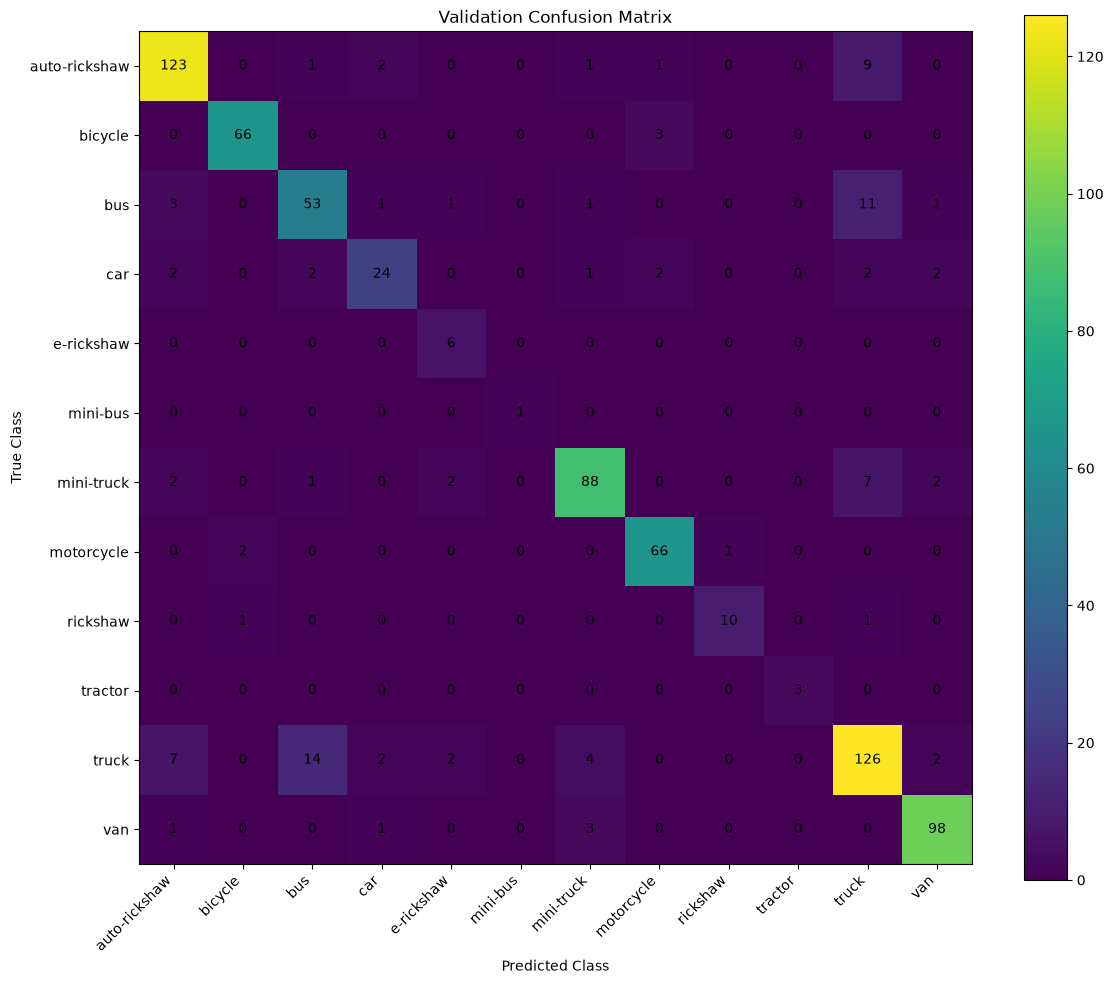

Confusion matrix saved to: c:\Users\divya\OneDrive\Desktop\CV_task_i2v\outputs\confusion_matrix.png


In [18]:
# Confusion Matrix

cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(12, 10))
plt.imshow(cm)

plt.title("Validation Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.xticks(
    range(len(classes)),
    classes,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(classes)),
    classes
)

# Add counts inside cells
for i in range(len(classes)):
    for j in range(len(classes)):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()

cm_path = OUTPUT_DIR / "confusion_matrix.png"
plt.savefig(cm_path, dpi=200, bbox_inches="tight")
plt.show()

print("Confusion matrix saved to:", cm_path)


### Experiment 2

In [19]:
# Augmented training transform
train_transform_aug = transforms.Compose([
    LetterboxTransform(224),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomAffine(
        degrees=10,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05)
    ),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

print("Augmented training transform created.")

Augmented training transform created.


In [20]:
train_dataset_aug = VehicleDataset(
    train_df,
    transform=train_transform_aug,
    class_to_idx=class_to_idx
)

train_loader_aug = DataLoader(
    train_dataset_aug,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

print("Augmented training loader created.")
print("Training batches:", len(train_loader_aug))

Augmented training loader created.
Training batches: 170


In [21]:
# Fresh MobileNetV3-Small for augmentation experiment

weights = MobileNet_V3_Small_Weights.DEFAULT

model_aug = mobilenet_v3_small(weights=weights)

in_features = model_aug.classifier[3].in_features

model_aug.classifier[3] = nn.Linear(
    in_features,
    len(classes)
)

model_aug = model_aug.to(device)

# Same class-weighted loss
criterion_aug = nn.CrossEntropyLoss(
    weight=class_weights
)

# Same optimizer settings
optimizer_aug = torch.optim.AdamW(
    model_aug.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

print("Fresh augmented model ready.")

Fresh augmented model ready.


In [22]:
NUM_EPOCHS_AUG = 20

history_aug = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_precision": [],
    "val_recall": [],
    "val_f1": []
}

best_f1_aug = -1

for epoch in range(NUM_EPOCHS_AUG):

    train_loss, train_accuracy = train_one_epoch(
        model_aug,
        train_loader_aug,
        criterion_aug,
        optimizer_aug,
        device
    )

    val_loss, val_accuracy, val_precision, val_recall, val_f1 = validate(
        model_aug,
        val_loader,
        criterion_aug,
        device
    )

    history_aug["train_loss"].append(train_loss)
    history_aug["train_accuracy"].append(train_accuracy)
    history_aug["val_loss"].append(val_loss)
    history_aug["val_accuracy"].append(val_accuracy)
    history_aug["val_precision"].append(val_precision)
    history_aug["val_recall"].append(val_recall)
    history_aug["val_f1"].append(val_f1)

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS_AUG}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val Precision: {val_precision:.4f} | "
        f"Val Recall: {val_recall:.4f} | "
        f"Val F1: {val_f1:.4f}"
    )

    if val_f1 > best_f1_aug:
        best_f1_aug = val_f1

        torch.save(
            model_aug.state_dict(),
            MODEL_DIR / "mobilenet_v3_small_aug_best.pth"
        )

        print("  → Best augmented model saved.")

Epoch [1/20] | Train Loss: 1.9567 | Train Acc: 0.4229 | Val Loss: 1.2572 | Val Acc: 0.6392 | Val Precision: 0.5232 | Val Recall: 0.6196 | Val F1: 0.5281
  → Best augmented model saved.
Epoch [2/20] | Train Loss: 1.0920 | Train Acc: 0.6594 | Val Loss: 0.8156 | Val Acc: 0.7320 | Val Precision: 0.7179 | Val Recall: 0.8275 | Val F1: 0.7394
  → Best augmented model saved.
Epoch [3/20] | Train Loss: 0.7702 | Train Acc: 0.7392 | Val Loss: 0.7281 | Val Acc: 0.7595 | Val Precision: 0.6654 | Val Recall: 0.8482 | Val F1: 0.7013
Epoch [4/20] | Train Loss: 0.5802 | Train Acc: 0.7848 | Val Loss: 0.6262 | Val Acc: 0.7869 | Val Precision: 0.7005 | Val Recall: 0.8726 | Val F1: 0.7459
  → Best augmented model saved.
Epoch [5/20] | Train Loss: 0.4617 | Train Acc: 0.8227 | Val Loss: 0.5689 | Val Acc: 0.8026 | Val Precision: 0.7120 | Val Recall: 0.8697 | Val F1: 0.7595
  → Best augmented model saved.
Epoch [6/20] | Train Loss: 0.3838 | Train Acc: 0.8459 | Val Loss: 0.5147 | Val Acc: 0.8248 | Val Precision:

In [23]:
best_model_aug = mobilenet_v3_small(weights=None)

in_features = best_model_aug.classifier[3].in_features

best_model_aug.classifier[3] = nn.Linear(
    in_features,
    len(classes)
)

best_model_aug.load_state_dict(
    torch.load(
        MODEL_DIR / "mobilenet_v3_small_aug_best.pth",
        map_location=device
    )
)

best_model_aug = best_model_aug.to(device)
best_model_aug.eval()

print("Best augmented model loaded successfully.")

Best augmented model loaded successfully.


In [24]:
# Generate predictions and probabilities for the augmented model

best_model_aug.eval()

all_labels_aug = []
all_predictions_aug = []
all_probabilities_aug = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = best_model_aug(images)

        probabilities = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)

        all_labels_aug.extend(labels.numpy())
        all_predictions_aug.extend(predictions.cpu().numpy())
        all_probabilities_aug.extend(probabilities.cpu().numpy())

all_labels_aug = np.array(all_labels_aug)
all_predictions_aug = np.array(all_predictions_aug)
all_probabilities_aug = np.array(all_probabilities_aug)

print("Augmented model evaluation complete.")
print("Validation images:", len(all_labels_aug))
print("Probability shape:", all_probabilities_aug.shape)

Augmented model evaluation complete.
Validation images: 765
Probability shape: (765, 12)


In [25]:
# Overall metrics for augmented model

aug_accuracy = accuracy_score(
    all_labels_aug,
    all_predictions_aug
)

aug_precision = precision_score(
    all_labels_aug,
    all_predictions_aug,
    average="macro",
    zero_division=0
)

aug_recall = recall_score(
    all_labels_aug,
    all_predictions_aug,
    average="macro",
    zero_division=0
)

aug_f1 = f1_score(
    all_labels_aug,
    all_predictions_aug,
    average="macro",
    zero_division=0
)

aug_map = average_precision_score(
    np.eye(len(classes))[all_labels_aug],
    all_probabilities_aug,
    average="macro"
)

print("Augmented Model Validation Metrics")
print("-" * 45)
print(f"Accuracy  : {aug_accuracy:.4f} ({aug_accuracy * 100:.2f}%)")
print(f"Precision : {aug_precision:.4f} ({aug_precision * 100:.2f}%)")
print(f"Recall    : {aug_recall:.4f} ({aug_recall * 100:.2f}%)")
print(f"F1 Score  : {aug_f1:.4f} ({aug_f1 * 100:.2f}%)")
print(f"mAP       : {aug_map:.4f} ({aug_map * 100:.2f}%)")

Augmented Model Validation Metrics
---------------------------------------------
Accuracy  : 0.8810 (88.10%)
Precision : 0.8270 (82.70%)
Recall    : 0.8973 (89.73%)
F1 Score  : 0.8496 (84.96%)
mAP       : 0.9489 (94.89%)


In [26]:
aug_report = classification_report(
    all_labels_aug,
    all_predictions_aug,
    target_names=classes,
    zero_division=0,
    digits=4
)

print(aug_report)

               precision    recall  f1-score   support

auto-rickshaw     0.9431    0.8467    0.8923       137
      bicycle     0.9848    0.9420    0.9630        69
          bus     0.8028    0.8028    0.8028        71
          car     0.8438    0.7714    0.8060        35
   e-rickshaw     0.6667    1.0000    0.8000         6
     mini-bus     0.5000    1.0000    0.6667         1
   mini-truck     0.8878    0.8529    0.8700       102
   motorcycle     0.8816    0.9710    0.9241        69
     rickshaw     0.9000    0.7500    0.8182        12
      tractor     0.7500    1.0000    0.8571         3
        truck     0.8023    0.8790    0.8389       157
          van     0.9608    0.9515    0.9561       103

     accuracy                         0.8810       765
    macro avg     0.8270    0.8973    0.8496       765
 weighted avg     0.8857    0.8810    0.8816       765



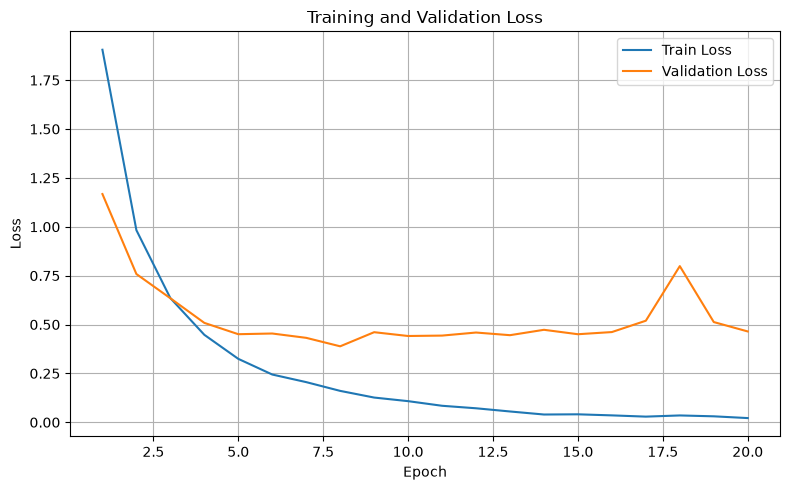

Saved: c:\Users\divya\OneDrive\Desktop\CV_task_i2v\outputs\loss_curve.png


In [27]:
# Learning curves for the original model

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], label="Train Loss")
plt.plot(epochs, history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

loss_curve_path = OUTPUT_DIR / "loss_curve.png"
plt.savefig(loss_curve_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", loss_curve_path)

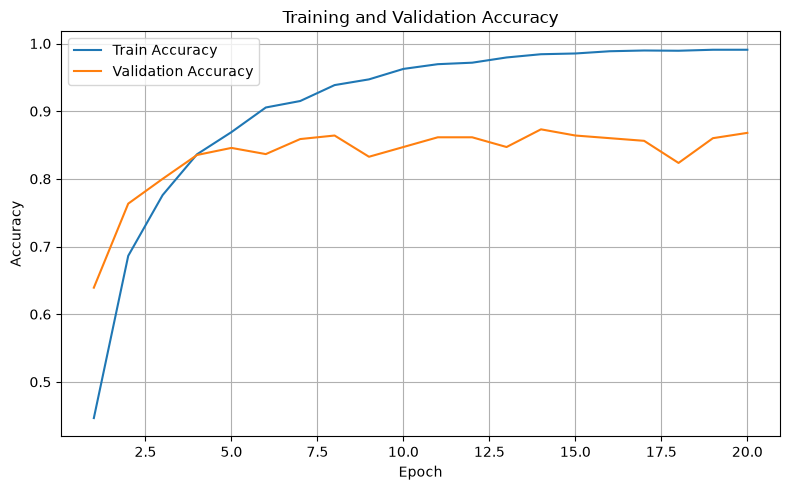

Saved: c:\Users\divya\OneDrive\Desktop\CV_task_i2v\outputs\accuracy_curve.png


In [28]:
# Accuracy learning curve for the original model

plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_accuracy"], label="Train Accuracy")
plt.plot(epochs, history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()

accuracy_curve_path = OUTPUT_DIR / "accuracy_curve.png"
plt.savefig(accuracy_curve_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", accuracy_curve_path)

In [29]:
# Save class names in prediction-index order

classes_path = OUTPUT_DIR / "classes.txt"

with open(classes_path, "w", encoding="utf-8") as f:
    for class_name in classes:
        f.write(class_name + "\n")

print("classes.txt saved to:")
print(classes_path)

print("\nContents:")
with open(classes_path, "r", encoding="utf-8") as f:
    print(f.read())

classes.txt saved to:
c:\Users\divya\OneDrive\Desktop\CV_task_i2v\outputs\classes.txt

Contents:
auto-rickshaw
bicycle
bus
car
e-rickshaw
mini-bus
mini-truck
motorcycle
rickshaw
tractor
truck
van



In [30]:
# Load the selected final model checkpoint

final_model = mobilenet_v3_small(weights=None)

in_features = final_model.classifier[3].in_features

final_model.classifier[3] = nn.Linear(
    in_features,
    len(classes)
)

final_model.load_state_dict(
    torch.load(
        MODEL_DIR / "mobilenet_v3_small_best.pth",
        map_location=device
    )
)

final_model = final_model.to(device)
final_model.eval()

print("Final model loaded successfully.")
print("Classes:", len(classes))
print("Input size: 3 x 224 x 224")

Final model loaded successfully.
Classes: 12
Input size: 3 x 224 x 224


### Export final model (Exp. 1) to ONNX

In [32]:
import onnx
import onnxruntime

print("ONNX version:", onnx.__version__)
print("ONNX Runtime version:", onnxruntime.__version__)

ONNX version: 1.23.0
ONNX Runtime version: 1.30.0


In [34]:
import onnx
from pathlib import Path

onnx_path = MODEL_DIR / "vehicle_classifier.onnx"

# Dummy input with the same shape used during training
dummy_input = torch.randn(1, 3, 224, 224, device=device)

torch.onnx.export(
    final_model,
    dummy_input,
    onnx_path,
    export_params=True,
    opset_version=17,
    do_constant_folding=True,
    input_names=["input"],
    output_names=["output"],
    dynamic_axes={
        "input": {0: "batch_size"},
        "output": {0: "batch_size"}
    }
)

print("ONNX model exported to:")
print(onnx_path)
print(f"File exists: {onnx_path.exists()}")
print(f"File size: {onnx_path.stat().st_size / (1024**2):.2f} MB")

C:\Users\divya\AppData\Local\Temp\ipykernel_14972\2579266868.py:9: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
W0925 21:29:23.431000 14972 Lib\site-packages\torch\onnx\_internal\exporter\_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 17 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


[torch.onnx] Obtain model graph for `MobileNetV3([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `MobileNetV3([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


The model version conversion is not supported by the onnxscript version converter and fallback is enabled. The model will be converted using the onnx C API (target version: 17).


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅


Failed to convert the model to the target version 17 using the ONNX C API. The model was not modified
Traceback (most recent call last):
  File "c:\Users\divya\OneDrive\Desktop\CV_task_i2v\.venv\Lib\site-packages\onnxscript\version_converter\__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
                      ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\divya\OneDrive\Desktop\CV_task_i2v\.venv\Lib\site-packages\onnxscript\version_converter\_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
             ^^^^^^^^^^^
  File "c:\Users\divya\OneDrive\Desktop\CV_task_i2v\.venv\Lib\site-packages\onnxscript\version_converter\__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\divya\OneDrive\Desktop\CV_task_i2v\.venv\Lib\site-packages\onnx\version_converter.py", line 39, in convert_version
    converted_model_str = C.convert_

[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
ONNX model exported to:
c:\Users\divya\OneDrive\Desktop\CV_task_i2v\models\vehicle_classifier.onnx
File exists: True
File size: 0.30 MB


In [35]:
import onnx

onnx_model = onnx.load(str(onnx_path))
onnx.checker.check_model(onnx_model)

print("ONNX model is valid.")
print("IR version:", onnx_model.ir_version)
print("Opset version:", onnx_model.opset_import[0].version)

ONNX model is valid.
IR version: 10
Opset version: 18


In [36]:
import onnxruntime as ort
import numpy as np

# Load ONNX model
session = ort.InferenceSession(
    str(onnx_path),
    providers=["CPUExecutionProvider"]
)

# Use one already-preprocessed validation image
sample_image, sample_label = val_dataset[0]

# Add batch dimension
sample_input = sample_image.unsqueeze(0).numpy()

# PyTorch prediction
with torch.no_grad():
    pytorch_output = final_model(
        torch.from_numpy(sample_input).to(device)
    ).cpu().numpy()

# ONNX prediction
onnx_output = session.run(
    ["output"],
    {"input": sample_input}
)[0]

# Compare
pytorch_prediction = np.argmax(pytorch_output, axis=1)[0]
onnx_prediction = np.argmax(onnx_output, axis=1)[0]

max_difference = np.max(
    np.abs(pytorch_output - onnx_output)
)

print("PyTorch predicted class:", idx_to_class[pytorch_prediction])
print("ONNX predicted class:  ", idx_to_class[onnx_prediction])
print("PyTorch class index:   ", pytorch_prediction)
print("ONNX class index:      ", onnx_prediction)
print("Maximum output difference:", max_difference)

print("\nPrediction matches:",
      pytorch_prediction == onnx_prediction)

PyTorch predicted class: auto-rickshaw
ONNX predicted class:   auto-rickshaw
PyTorch class index:    0
ONNX class index:       0
Maximum output difference: 1.66893e-05

Prediction matches: True


In [37]:
from PIL import Image
import torch
import numpy as np

verification_dir = PROJECT_DIR / "verification_images"

verification_images = [
    "autorickshaw.png",
    "car.png",
    "van.png"
]

for image_name in verification_images:
    image_path = verification_dir / image_name

    image = Image.open(image_path).convert("RGB")
    image_tensor = val_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        output = final_model(image_tensor)
        probabilities = torch.softmax(output, dim=1)

    pred_index = probabilities.argmax(dim=1).item()
    confidence = probabilities[0, pred_index].item()

    print(
        f"{image_name:20s} -> "
        f"{idx_to_class[pred_index]:15s} "
        f"{confidence:.4f}"
    )

autorickshaw.png     -> truck           0.7944
car.png              -> car             0.9994
van.png              -> car             0.7762


In [38]:
for image_name in verification_images:
    image_path = verification_dir / image_name

    image = Image.open(image_path).convert("RGB")
    image_tensor = val_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        output = final_model(image_tensor)
        probabilities = torch.softmax(output, dim=1)[0]

    top_probs, top_indices = torch.topk(probabilities, 5)

    print(f"\n{image_name}")
    print("-" * 40)

    for prob, idx in zip(top_probs, top_indices):
        print(f"{idx_to_class[idx.item()]:15s}: {prob.item():.4f}")


autorickshaw.png
----------------------------------------
truck          : 0.7944
bus            : 0.1433
auto-rickshaw  : 0.0348
mini-bus       : 0.0172
car            : 0.0097

car.png
----------------------------------------
car            : 0.9994
van            : 0.0003
mini-truck     : 0.0002
mini-bus       : 0.0000
truck          : 0.0000

van.png
----------------------------------------
car            : 0.7762
bus            : 0.1198
truck          : 0.0799
motorcycle     : 0.0072
mini-bus       : 0.0065


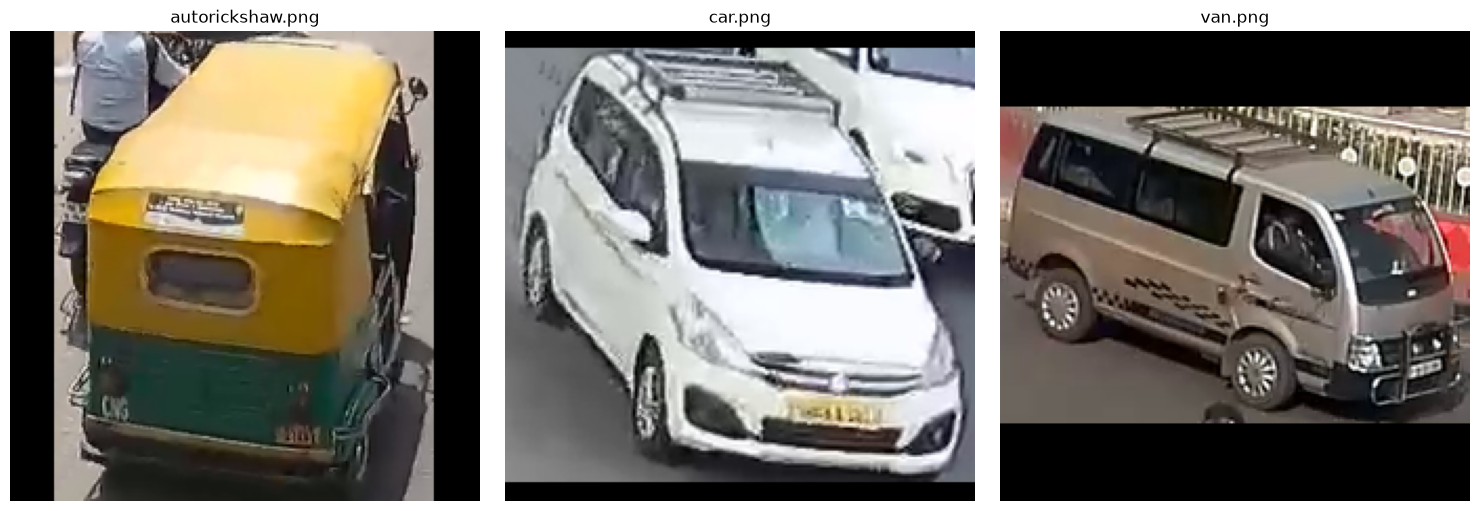

In [39]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, image_name in zip(axes, verification_images):
    image_path = verification_dir / image_name

    image = Image.open(image_path).convert("RGB")
    processed = val_transform(image)

    # Undo ImageNet normalization for visualization
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    display_image = processed * std + mean
    display_image = display_image.clamp(0, 1)

    ax.imshow(display_image.permute(1, 2, 0))
    ax.set_title(image_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [40]:
# testing augmented model

# Load the augmented model
aug_model = mobilenet_v3_small(weights=None)

in_features = aug_model.classifier[3].in_features
aug_model.classifier[3] = nn.Linear(in_features, len(classes))

aug_model.load_state_dict(
    torch.load(
        MODEL_DIR / "mobilenet_v3_small_aug_best.pth",
        map_location=device
    )
)

aug_model = aug_model.to(device)
aug_model.eval()

print("Augmented model loaded successfully.")

Augmented model loaded successfully.


In [41]:
# Compare augmented model predictions on verification images

for image_name in verification_images:
    image_path = verification_dir / image_name

    image = Image.open(image_path).convert("RGB")
    image_tensor = val_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        output = aug_model(image_tensor)
        probabilities = torch.softmax(output, dim=1)[0]

    top_probs, top_indices = torch.topk(probabilities, 5)

    print(f"\n{image_name}")
    print("-" * 40)

    for prob, idx in zip(top_probs, top_indices):
        print(
            f"{idx_to_class[idx.item()]:15s}: "
            f"{prob.item():.4f}"
        )


autorickshaw.png
----------------------------------------
truck          : 0.4959
auto-rickshaw  : 0.4617
bus            : 0.0337
mini-truck     : 0.0032
rickshaw       : 0.0015

car.png
----------------------------------------
car            : 0.9807
mini-truck     : 0.0111
van            : 0.0049
truck          : 0.0018
auto-rickshaw  : 0.0005

van.png
----------------------------------------
bus            : 0.8484
truck          : 0.0923
mini-truck     : 0.0546
auto-rickshaw  : 0.0013
rickshaw       : 0.0012


### Experiment 3

In [42]:
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

# Load ImageNet-pretrained EfficientNet-B0
efficient_weights = EfficientNet_B0_Weights.DEFAULT

efficient_model = efficientnet_b0(weights=efficient_weights)

# Replace the final classifier for our 12 vehicle classes
in_features = efficient_model.classifier[1].in_features
efficient_model.classifier[1] = nn.Linear(
    in_features,
    len(classes)
)

efficient_model = efficient_model.to(device)

print("EfficientNet-B0 loaded successfully.")
print("Number of classes:", len(classes))
print("Classifier input features:", in_features)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\divya/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:02<00:00, 8.46MB/s]


EfficientNet-B0 loaded successfully.
Number of classes: 12
Classifier input features: 1280


In [43]:
# Loss and optimizer for EfficientNet-B0

efficient_criterion = nn.CrossEntropyLoss(
    weight=class_weights.to(device)
)

efficient_optimizer = torch.optim.AdamW(
    efficient_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

EFFICIENT_EPOCHS = 20

efficient_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_precision": [],
    "val_recall": [],
    "val_f1": []
}

best_efficient_f1 = -1.0

efficient_checkpoint_path = (
    MODEL_DIR / "efficientnet_b0_best.pth"
)

print("Training setup ready.")
print("Epochs:", EFFICIENT_EPOCHS)
print("Checkpoint:", efficient_checkpoint_path)

Training setup ready.
Epochs: 20
Checkpoint: c:\Users\divya\OneDrive\Desktop\CV_task_i2v\models\efficientnet_b0_best.pth


In [44]:
for epoch in range(EFFICIENT_EPOCHS):

    train_loss, train_acc = train_one_epoch(
        efficient_model,
        train_loader,
        efficient_criterion,
        efficient_optimizer,
        device
    )

    val_loss, val_acc, val_precision, val_recall, val_f1 = validate(
        efficient_model,
        val_loader,
        efficient_criterion,
        device
    )

    efficient_history["train_loss"].append(train_loss)
    efficient_history["train_accuracy"].append(train_acc)
    efficient_history["val_loss"].append(val_loss)
    efficient_history["val_accuracy"].append(val_acc)
    efficient_history["val_precision"].append(val_precision)
    efficient_history["val_recall"].append(val_recall)
    efficient_history["val_f1"].append(val_f1)

    # Save the best model based on macro F1
    if val_f1 > best_efficient_f1:
        best_efficient_f1 = val_f1

        torch.save(
            efficient_model.state_dict(),
            efficient_checkpoint_path
        )

        best_marker = " <-- BEST"

    else:
        best_marker = ""

    print(
        f"Epoch {epoch + 1:02d}/{EFFICIENT_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Precision: {val_precision:.4f} | "
        f"Val Recall: {val_recall:.4f} | "
        f"Val F1: {val_f1:.4f}"
        f"{best_marker}"
    )

Epoch 01/20 | Train Loss: 1.8991 | Train Acc: 0.4892 | Val Loss: 1.1513 | Val Acc: 0.7399 | Val Precision: 0.7064 | Val Recall: 0.8005 | Val F1: 0.7066 <-- BEST
Epoch 02/20 | Train Loss: 0.9217 | Train Acc: 0.7220 | Val Loss: 0.6993 | Val Acc: 0.7804 | Val Precision: 0.7451 | Val Recall: 0.8561 | Val F1: 0.7797 <-- BEST
Epoch 03/20 | Train Loss: 0.5211 | Train Acc: 0.8198 | Val Loss: 0.4944 | Val Acc: 0.8405 | Val Precision: 0.8313 | Val Recall: 0.8860 | Val F1: 0.8471 <-- BEST
Epoch 04/20 | Train Loss: 0.3224 | Train Acc: 0.8801 | Val Loss: 0.4164 | Val Acc: 0.8732 | Val Precision: 0.8712 | Val Recall: 0.9194 | Val F1: 0.8891 <-- BEST
Epoch 05/20 | Train Loss: 0.2436 | Train Acc: 0.9092 | Val Loss: 0.4124 | Val Acc: 0.8641 | Val Precision: 0.7992 | Val Recall: 0.9062 | Val F1: 0.8276
Epoch 06/20 | Train Loss: 0.1670 | Train Acc: 0.9312 | Val Loss: 0.3974 | Val Acc: 0.8810 | Val Precision: 0.8885 | Val Recall: 0.8961 | Val F1: 0.8914 <-- BEST
Epoch 07/20 | Train Loss: 0.1329 | Train Ac

KeyboardInterrupt: 

In [45]:
# Load the best EfficientNet-B0 checkpoint
checkpoint_path = MODEL_DIR / "efficientnet_b0_best.pth"

efficient_model.load_state_dict(
    torch.load(checkpoint_path, map_location=device)
)

efficient_model.eval()

print("Best EfficientNet-B0 checkpoint loaded successfully!")

Best EfficientNet-B0 checkpoint loaded successfully!



Image: autorickshaw.png
  truck: 0.7782
  auto-rickshaw: 0.1184
  bus: 0.0886
  car: 0.0039
  tractor: 0.0027


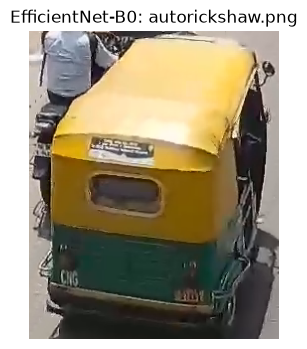


Image: car.png
  car: 0.9998
  van: 0.0001
  motorcycle: 0.0000
  truck: 0.0000
  mini-truck: 0.0000


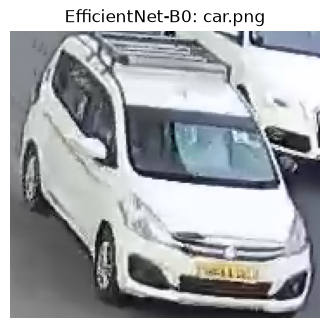


Image: van.png
  truck: 0.5278
  car: 0.2615
  bus: 0.1110
  van: 0.0827
  auto-rickshaw: 0.0068


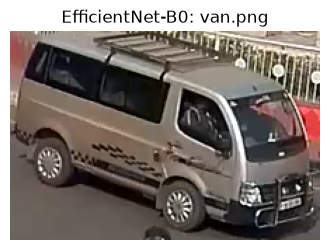

In [49]:
from PIL import Image
import torch
import matplotlib.pyplot as plt
from pathlib import Path

efficient_model.eval()

verification_dir = Path(
    r"C:\Users\divya\OneDrive\Desktop\CV_task_i2v\verification_images"
)

for filename in ["autorickshaw.png", "car.png", "van.png"]:
    image_path = verification_dir / filename

    image = Image.open(image_path).convert("RGB")
    input_tensor = val_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = efficient_model(input_tensor)
        probabilities = torch.softmax(outputs, dim=1)[0]

    top_probs, top_indices = torch.topk(probabilities, 5)

    print(f"\nImage: {filename}")
    for prob, idx in zip(top_probs, top_indices):
        print(f"  {classes[idx.item()]}: {prob.item():.4f}")

    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.title(f"EfficientNet-B0: {filename}")
    plt.axis("off")
    plt.show()

In [55]:
# Load best EfficientNet-B0 checkpoint
efficient_model.load_state_dict(
    torch.load(
        MODEL_DIR / "efficientnet_b0_best.pth",
        map_location=device
    )
)

efficient_model = efficient_model.to(device)
efficient_model.eval()

efficient_labels = []
efficient_predictions = []
efficient_probabilities = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = efficient_model(images)
        probabilities = torch.softmax(outputs, dim=1)
        predictions = torch.argmax(probabilities, dim=1)

        efficient_labels.extend(labels.numpy())
        efficient_predictions.extend(predictions.cpu().numpy())
        efficient_probabilities.extend(probabilities.cpu().numpy())

efficient_labels = np.array(efficient_labels)
efficient_predictions = np.array(efficient_predictions)
efficient_probabilities = np.array(efficient_probabilities)

efficient_accuracy = accuracy_score(
    efficient_labels,
    efficient_predictions
)

efficient_precision = precision_score(
    efficient_labels,
    efficient_predictions,
    average="macro",
    zero_division=0
)

efficient_recall = recall_score(
    efficient_labels,
    efficient_predictions,
    average="macro",
    zero_division=0
)

efficient_f1 = f1_score(
    efficient_labels,
    efficient_predictions,
    average="macro",
    zero_division=0
)

efficient_one_hot = np.eye(len(classes))[efficient_labels]

efficient_map = average_precision_score(
    efficient_one_hot,
    efficient_probabilities,
    average="macro"
)

print("\n========== EFFICIENTNET-B0 BEST CHECKPOINT ==========")
print(f"Accuracy        : {efficient_accuracy:.4f} ({efficient_accuracy * 100:.2f}%)")
print(f"Macro Precision : {efficient_precision:.4f} ({efficient_precision * 100:.2f}%)")
print(f"Macro Recall    : {efficient_recall:.4f} ({efficient_recall * 100:.2f}%)")
print(f"Macro F1        : {efficient_f1:.4f} ({efficient_f1 * 100:.2f}%)")
print(f"Macro mAP       : {efficient_map:.4f} ({efficient_map * 100:.2f}%)")


========== EFFICIENTNET-B0 BEST CHECKPOINT ==========
Accuracy        : 0.8810 (88.10%)
Macro Precision : 0.8885 (88.85%)
Macro Recall    : 0.8961 (89.61%)
Macro F1        : 0.8914 (89.14%)
Macro mAP       : 0.9511 (95.11%)


## Final model- MobileNetV3-Small

In [51]:
# Load the selected final model checkpoint

final_model = mobilenet_v3_small(weights=None)

in_features = final_model.classifier[3].in_features

final_model.classifier[3] = nn.Linear(
    in_features,
    len(classes)
)

final_model.load_state_dict(
    torch.load(
        MODEL_DIR / "mobilenet_v3_small_best.pth",
        map_location=device
    )
)

final_model = final_model.to(device)
final_model.eval()

print("Final model loaded successfully.")
print("Classes:", len(classes))
print("Input size: 3 x 224 x 224")

Final model loaded successfully.
Classes: 12
Input size: 3 x 224 x 224


In [52]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    classification_report
)
import numpy as np
import torch

final_model.eval()

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = final_model(images)
        probabilities = torch.softmax(outputs, dim=1)
        predictions = torch.argmax(probabilities, dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)

# Overall metrics
accuracy = accuracy_score(all_labels, all_predictions)

precision = precision_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

# Macro mAP
labels_one_hot = np.eye(len(classes))[all_labels]

map_macro = average_precision_score(
    labels_one_hot,
    all_probabilities,
    average="macro"
)

print("\n========== FINAL VALIDATION RESULTS ==========")
print(f"Accuracy        : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro Precision : {precision:.4f} ({precision * 100:.2f}%)")
print(f"Macro Recall    : {recall:.4f} ({recall * 100:.2f}%)")
print(f"Macro F1        : {f1:.4f} ({f1 * 100:.2f}%)")
print(f"Macro mAP       : {map_macro:.4f} ({map_macro * 100:.2f}%)")

print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=classes,
        digits=4,
        zero_division=0
    )
)


========== FINAL VALIDATION RESULTS ==========
Accuracy        : 0.8680 (86.80%)
Macro Precision : 0.8670 (86.70%)
Macro Recall    : 0.8911 (89.11%)
Macro F1        : 0.8729 (87.29%)
Macro mAP       : 0.9504 (95.04%)

========== CLASSIFICATION REPORT ==========
               precision    recall  f1-score   support

auto-rickshaw     0.8913    0.8978    0.8945       137
      bicycle     0.9565    0.9565    0.9565        69
          bus     0.7465    0.7465    0.7465        71
          car     0.8000    0.6857    0.7385        35
   e-rickshaw     0.5455    1.0000    0.7059         6
     mini-bus     1.0000    1.0000    1.0000         1
   mini-truck     0.8980    0.8627    0.8800       102
   motorcycle     0.9167    0.9565    0.9362        69
     rickshaw     0.9091    0.8333    0.8696        12
      tractor     1.0000    1.0000    1.0000         3
        truck     0.8077    0.8025    0.8051       157
          van     0.9333    0.9515    0.9423       103

     accuracy       

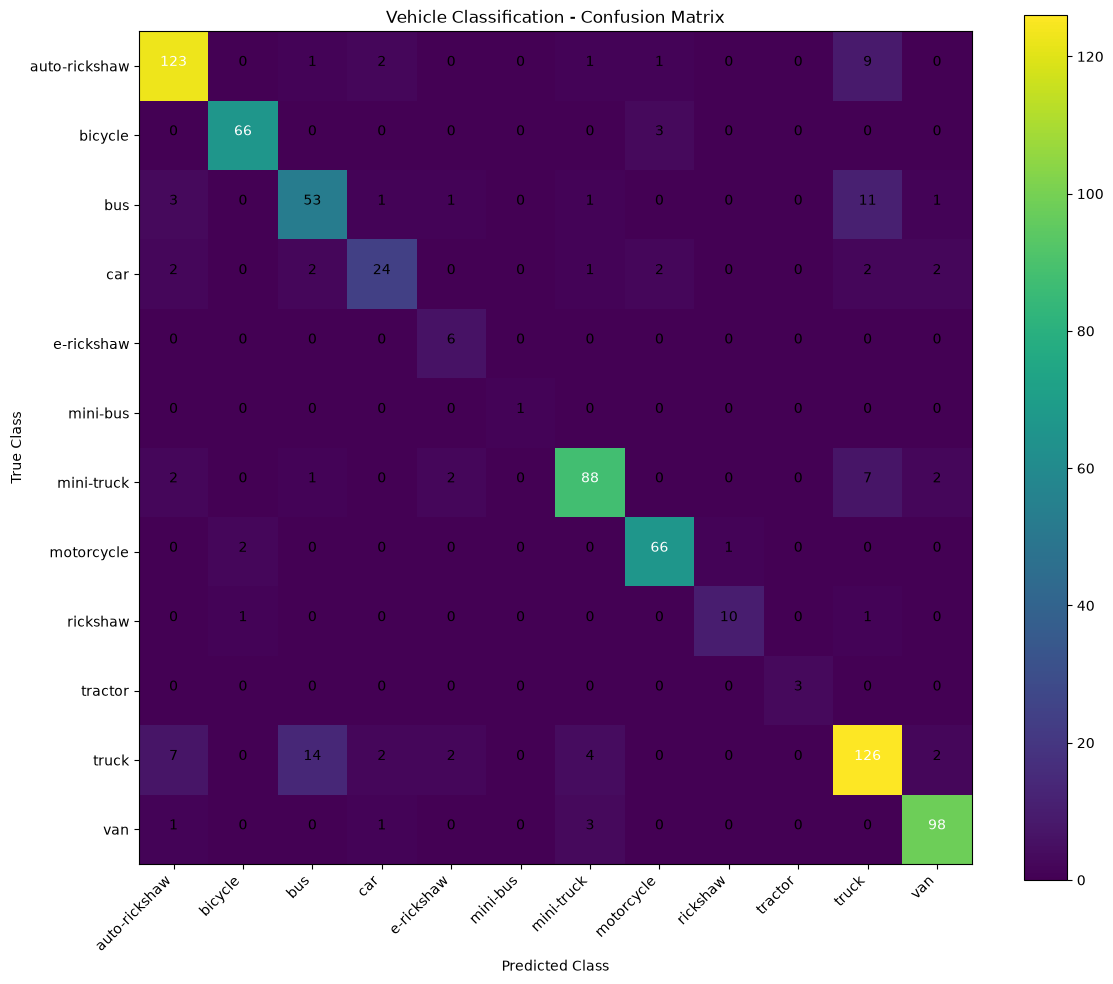

Confusion matrix saved to:
c:\Users\divya\OneDrive\Desktop\CV_task_i2v\outputs\confusion_matrix.png


In [53]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(figsize=(12, 10))

plt.imshow(cm, interpolation="nearest")
plt.title("Vehicle Classification - Confusion Matrix")
plt.colorbar()

tick_marks = np.arange(len(classes))

plt.xticks(
    tick_marks,
    classes,
    rotation=45,
    ha="right"
)

plt.yticks(
    tick_marks,
    classes
)

# Add values inside cells
threshold = cm.max() / 2

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j,
            i,
            cm[i, j],
            horizontalalignment="center",
            color="white" if cm[i, j] > threshold else "black"
        )

plt.ylabel("True Class")
plt.xlabel("Predicted Class")
plt.tight_layout()

confusion_matrix_path = OUTPUT_DIR / "confusion_matrix.png"

plt.savefig(
    confusion_matrix_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved to:")
print(confusion_matrix_path)

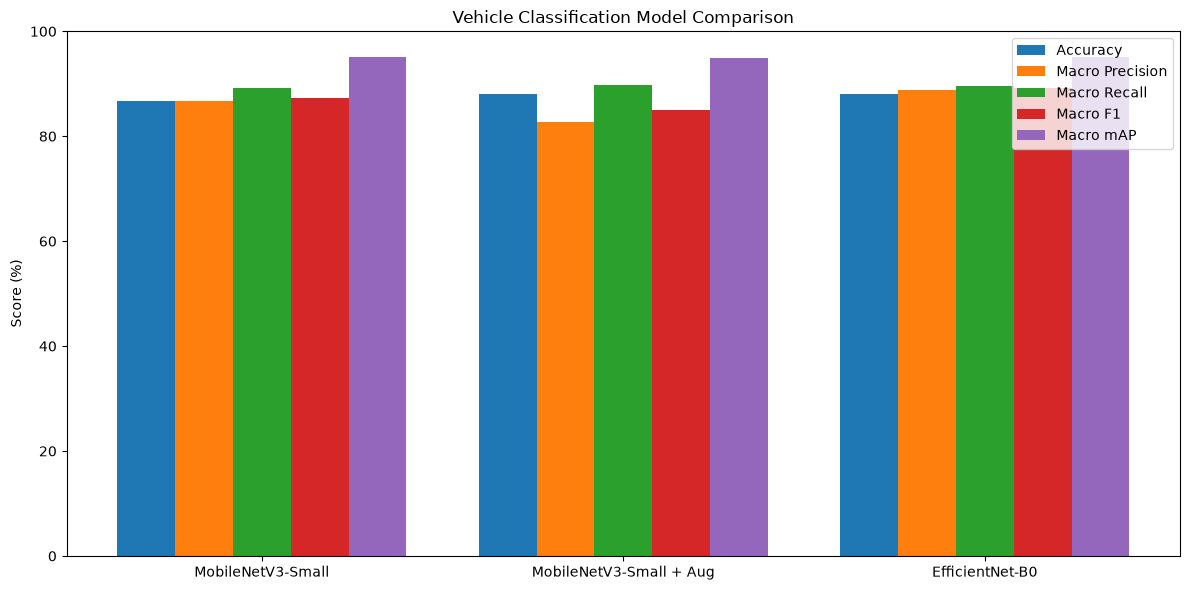

Updated comparison plot saved to:
c:\Users\divya\OneDrive\Desktop\CV_task_i2v\outputs\model_comparison.png


In [56]:
import matplotlib.pyplot as plt

model_names = [
    "MobileNetV3-Small",
    "MobileNetV3-Small + Aug",
    "EfficientNet-B0"
]

accuracy_values = [86.80, 88.10, 88.10]
precision_values = [86.70, 82.70, 88.85]
recall_values = [89.11, 89.73, 89.61]
f1_values = [87.29, 84.96, 89.14]
map_values = [95.04, 94.89, 95.11]

x = range(len(model_names))
width = 0.16

plt.figure(figsize=(12, 6))

plt.bar(
    [i - 2 * width for i in x],
    accuracy_values,
    width,
    label="Accuracy"
)

plt.bar(
    [i - width for i in x],
    precision_values,
    width,
    label="Macro Precision"
)

plt.bar(
    x,
    recall_values,
    width,
    label="Macro Recall"
)

plt.bar(
    [i + width for i in x],
    f1_values,
    width,
    label="Macro F1"
)

plt.bar(
    [i + 2 * width for i in x],
    map_values,
    width,
    label="Macro mAP"
)

plt.xticks(list(x), model_names)
plt.ylabel("Score (%)")
plt.title("Vehicle Classification Model Comparison")
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()

comparison_path = OUTPUT_DIR / "model_comparison.png"

plt.savefig(
    comparison_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Updated comparison plot saved to:")
print(comparison_path)